# MODIS data acquisition
For this analysis, we need precise overpass times. This is only possible if we use the granule-level data rather than the mosaic "snapshots" data. This notebook takes a bounding box in polar stereographic coordinates and selects the granule whose daytime overpass falls between 11 and 14 hours, which is approximately the time of the images used in prior IFT analyses. There are built-in tools in the SatPy library for constructing composites. A true-color composite with corrected reflectance is included. I am beginning the analysis using the images from the Aqua satellite only, so that the workflow can be in place. I use the requests library to download the images

In [11]:
from datetime import datetime
import earthaccess
import geopandas as gpd
import numpy as np
import os
import pandas as pd
import pyproj
from pyproj import Transformer
from pyresample import create_area_def
import rasterio as rio
import re
from satpy.scene import Scene
import shapely.geometry as sg
import shapely.ops as so
import ultraplot as uplt
import xarray as xr

proj_LL = 'epsg:4326' # WGS 84 Ellipsoid
proj_XY = 'epsg:3413' # NSIDC Polar Stereographic
transform_to_ll = pyproj.Transformer.from_crs(proj_XY, proj_LL, always_xy=True)
# dataloc = "/Users/dwatkin2/Documents/research/data/modis_granules/greenland_sea_2024/"
dataloc = "/Users/dwatkin2/Documents/research/data/modis_granules/greenland_sea_2007-07-08_2007-07-11/"

In [2]:
# Option one: Zoomed-in scene 
# reference_img = rio.open("../data/MODIS-reference-2024-06-29.tiff")

# Option two: Full scene for FS 
reference_img = rio.open("../../data/MODIS-fram-strait-reference.tiff")
reference_img.bounds

BoundingBox(left=247326.39999999997, bottom=-2089884.906276994, right=1115678.4, top=-635714.0937230061)

In [4]:
##### Get bounding box lat/lon for earthaccess search
# Bounding box was defined in polar stereographic coordinates.
# Need to get lat lon for the earthdata search
left, bottom, right, top = reference_img.bounds
lower_left_lon, lower_left_lat = transform_to_ll.transform(left, bottom)
upper_right_lon, upper_right_lat = transform_to_ll.transform(right, top)

# Center point: Granule selection will only include scenes intersecting this point
center_lon, center_lat = transform_to_ll.transform(0.5*(left + right), 0.5 * (top + bottom))

In [5]:
lower_left_lon, lower_left_lat

(-38.25075106247927, 70.74891233350155)

In [6]:
upper_right_lon, upper_right_lat

(15.325488648190781, 78.18659970247242)

In [7]:
#### Define regridding area for SatPy ####
# Adjust extents to be an integer size
# Extents were identified from the ICEX2022 buoy dataset with a 100 km buffer
# Extent is definited as left x, lower y, right x, upper y
# We also round the image size to the nearest 1000 m.

dx = np.round(right - left)
dy = np.round(top - bottom)
dx = np.round(dx, -3)
dy = np.round(dy, -3)
x0 = np.round(left)
y0 = np.round(bottom)
integer_extents = (x0, y0, x0 + dx, y0 + dy)

area_id = 'nsidc_polar_north'
description = 'NSIDC Sea Ice Polar Stereographic North'
projection = 'EPSG:3413' 
resolution = 250
area = create_area_def(area_id=area_id, description=description, projection=projection, 
                resolution=resolution, area_extent=integer_extents)    

In [8]:
# Need the 250 m, 500 m, and 1000 m datasets for aqua and for terra

def get_shortname(satellite, resolution):
    if satellite == 'Terra':
        if resolution == '1000m':
            shortname = 'MOD021KM'
        elif resolution == '500m':
            shortname = 'MOD02HKM'
        elif resolution == '250m':
            shortname = 'MOD02QKM'
    elif satellite == 'Aqua':
        if resolution == '1000m':
            shortname = 'MYD021KM'
        elif resolution == '500m':
            shortname = 'MYD02HKM'
        elif resolution == '250m':
            shortname = 'MYD02QKM'
    return shortname


# Data download
Two steps: granules for 250 m and for 500 m resolution, for Aqua and for Terra. Selects all granules which overlap with the center point and the time window. Here, we download the granules to save to file, however we also have the option to stream directly into an xarray object in order to process the data before saving.

In [9]:
# Zoomed-in scene for Rebeca
# temporal_limits = ('2024-06-28 0:00', '2024-06-29 23:00')

# Case for intercomparison scene
temporal_limits = ('2007-07-08 0:00', '2007-07-11 23:00')
bounding_box = (lower_left_lon, lower_left_lat, upper_right_lon, upper_right_lat)
version = 6.1
earthaccess.login()  

In [10]:
# 250 m images
aqua_results = earthaccess.search_data(
            short_name=get_shortname('Aqua', '250m'), 
            cloud_hosted=True, 
            point=(center_lon, center_lat),
            temporal=temporal_limits,
            version=6.1
)

terra_results = earthaccess.search_data(
            short_name=get_shortname('Terra', '250m'), 
            cloud_hosted=True, 
            point=(center_lon, center_lat),
            temporal=temporal_limits,
            version=6.1
)
files = earthaccess.download(aqua_results, dataloc)
files = earthaccess.download(terra_results, dataloc)

QUEUEING TASKS | :   0%|          | 0/34 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/34 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/34 [00:00<?, ?it/s]

QUEUEING TASKS | :   0%|          | 0/34 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/34 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/34 [00:00<?, ?it/s]

In [12]:
# 500 m images
aqua_results = earthaccess.search_data(
            short_name=get_shortname('Aqua', '500m'), 
            cloud_hosted=True, 
            point=(center_lon, center_lat),
            temporal=temporal_limits,
            version=6.1
)

terra_results = earthaccess.search_data(
            short_name=get_shortname('Terra', '500m'), 
            cloud_hosted=True, 
            point=(center_lon, center_lat),
            temporal=temporal_limits,
            version=6.1
)
files = earthaccess.download(aqua_results, dataloc)
files = earthaccess.download(terra_results, dataloc)

QUEUEING TASKS | :   0%|          | 0/34 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/34 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/34 [00:00<?, ?it/s]

QUEUEING TASKS | :   0%|          | 0/34 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/34 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/34 [00:00<?, ?it/s]

In [13]:
# Georeference data
georeference_results = earthaccess.search_data(
            short_name='MOD03', 
            cloud_hosted=True, 
            point=(center_lon, center_lat),
            temporal=temporal_limits,
            version=6.1
)
earthaccess.download(georeference_results, dataloc)

QUEUEING TASKS | :   0%|          | 0/34 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/34 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/34 [00:00<?, ?it/s]

[PosixPath('/Users/dwatkin2/Documents/research/data/modis_granules/greenland_sea_2007-07-08_2007-07-11/MOD03.A2007189.0015.061.2017250181505.hdf'),
 PosixPath('/Users/dwatkin2/Documents/research/data/modis_granules/greenland_sea_2007-07-08_2007-07-11/MOD03.A2007189.1155.061.2017250182420.hdf'),
 PosixPath('/Users/dwatkin2/Documents/research/data/modis_granules/greenland_sea_2007-07-08_2007-07-11/MOD03.A2007189.1335.061.2017250182043.hdf'),
 PosixPath('/Users/dwatkin2/Documents/research/data/modis_granules/greenland_sea_2007-07-08_2007-07-11/MOD03.A2007189.1515.061.2017250181812.hdf'),
 PosixPath('/Users/dwatkin2/Documents/research/data/modis_granules/greenland_sea_2007-07-08_2007-07-11/MOD03.A2007189.1650.061.2017250182125.hdf'),
 PosixPath('/Users/dwatkin2/Documents/research/data/modis_granules/greenland_sea_2007-07-08_2007-07-11/MOD03.A2007189.1830.061.2017250182610.hdf'),
 PosixPath('/Users/dwatkin2/Documents/research/data/modis_granules/greenland_sea_2007-07-08_2007-07-11/MOD03.A20

In [14]:
georeference_results = earthaccess.search_data(
            short_name='MYD03', 
            cloud_hosted=True, 
            point=(center_lon, center_lat),
            temporal=temporal_limits,
            version=6.1
)
earthaccess.download(georeference_results, dataloc)

QUEUEING TASKS | :   0%|          | 0/34 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/34 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/34 [00:00<?, ?it/s]

[PosixPath('/Users/dwatkin2/Documents/research/data/modis_granules/greenland_sea_2007-07-08_2007-07-11/MYD03.A2007189.0230.061.2018040045928.hdf'),
 PosixPath('/Users/dwatkin2/Documents/research/data/modis_granules/greenland_sea_2007-07-08_2007-07-11/MYD03.A2007189.0410.061.2018040050041.hdf'),
 PosixPath('/Users/dwatkin2/Documents/research/data/modis_granules/greenland_sea_2007-07-08_2007-07-11/MYD03.A2007189.0545.061.2018040045920.hdf'),
 PosixPath('/Users/dwatkin2/Documents/research/data/modis_granules/greenland_sea_2007-07-08_2007-07-11/MYD03.A2007189.0725.061.2018040050001.hdf'),
 PosixPath('/Users/dwatkin2/Documents/research/data/modis_granules/greenland_sea_2007-07-08_2007-07-11/MYD03.A2007189.0900.061.2018040050441.hdf'),
 PosixPath('/Users/dwatkin2/Documents/research/data/modis_granules/greenland_sea_2007-07-08_2007-07-11/MYD03.A2007189.1040.061.2018040050641.hdf'),
 PosixPath('/Users/dwatkin2/Documents/research/data/modis_granules/greenland_sea_2007-07-08_2007-07-11/MYD03.A20

# Inspect downloaded data

In [22]:
import ultraplot as uplt
import pandas as pd
import os
import numpy as np
import rioxarray as rxr
# dataloc = "/Users/dwatkin2/Documents/research/data/modis_granules/greenland_sea_2024/"
dataloc = "/Users/dwatkin2/Documents/research/data/modis_granules/greenland_sea_2007-07-08_2007-07-11/"

In [16]:
def timestamp_from_modis_fname(fname):
    shortname, juliandate, hourmin, collection, juliandatetime, filetype = fname.split('.')
    hour = int(hourmin[0:2])
    minute = int(hourmin[2:4])
    julianday = int(juliandate[5:])
    year = int(juliandate[1:5])
    return pd.to_datetime(str(year) + '-01-01 00:00') + pd.to_timedelta(julianday + hour/24 + minute/(24*60) - 1, unit='D').round('1min')

def satellite_from_modis_fname(fname):
    if "MYD" in fname:
        return "Aqua"
    elif "MOD" in fname:
        return "Terra"

def resolution_from_modis_fname(fname):
    if "21KM" in fname:
        return 1000
    elif "2HKM" in fname:
        return 500
    elif "2QKM" in fname:
        return 250

In [18]:
files = [f for f in os.listdir(dataloc) if '.hdf' in f]
len(files)

204

In [19]:
df_granules = pd.DataFrame(
    {'datetime': [timestamp_from_modis_fname(f) for f in files],
     'satellite': [satellite_from_modis_fname(f) for f in files],
     'resolution': [resolution_from_modis_fname(f) for f in files],
     'filename': files}
)
df_granules = df_granules.sort_values("datetime")

'greenland_sea_2007-07-08_2007-07-11'

Number of scenes per satellite:
Aqua 34
Terra 34


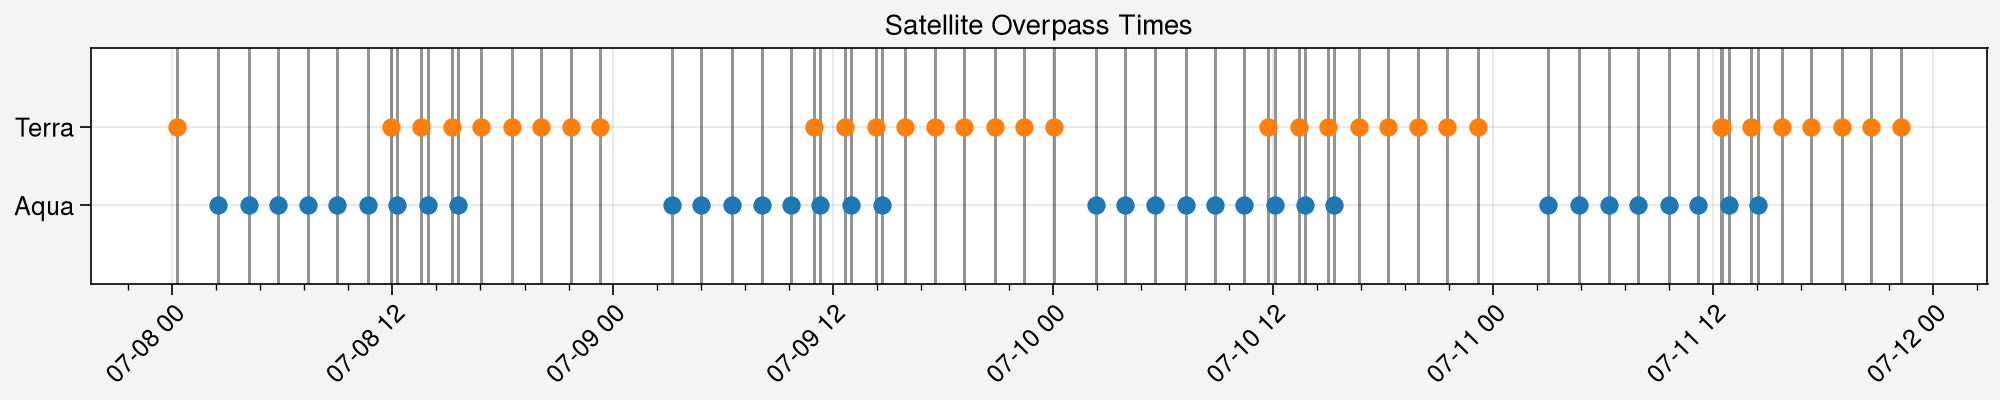

In [28]:

fig, ax = uplt.subplots(width=10, height=2)
idx = 1
for date in df_granules.datetime:
    ax.axvline(date, lw=1, color='gray', zorder=0)
print("Number of scenes per satellite:")
for satellite, data in df_granules.groupby("satellite"):
    data = data.loc[data.resolution == 250, :]
    print(satellite, len(data))
    ax.scatter(data.datetime, np.ones(len(data)) + idx/2, label=satellite, marker="o", zorder=2)
    idx += 1

ax.format(ylim=(1, 2.5), yticks=[1.5, 2], yformatter=["Aqua", "Terra"], xlabel='', xrotation=45, title="Satellite Overpass Times")
fig.save("../figures/" + dataloc.split('/')[-2] + '_overpass_times.png', dpi=300)